<a href="https://colab.research.google.com/github/okenoruk/BarCode-reader/blob/master/Image_enhanced_ipnyb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [3]:
from matplotlib import pyplot as plt

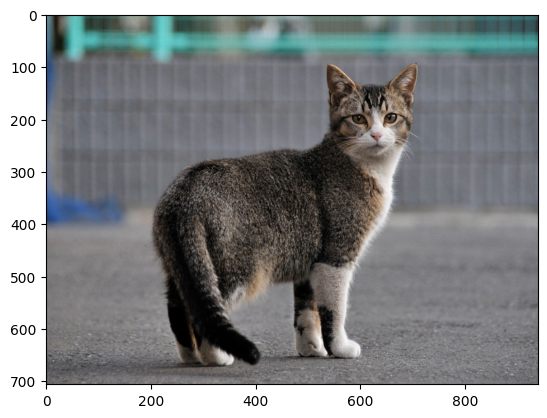

In [4]:
from PIL import Image
from PIL import ImageEnhance

# Opens the image file
image = '/content/drive/MyDrive/Image_proc/koceng.png'
image = Image.open(image)
# shows image in image viewer
#img = plt. imread('image.png')
plt.imshow(image)
#image.show()


# Enhance Brightness


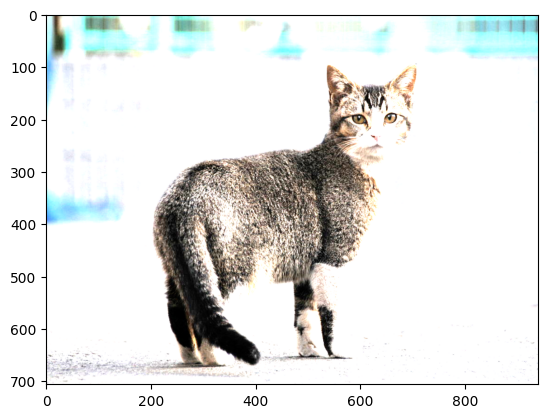

In [5]:
curr_bri = ImageEnhance.Brightness(image)
# new_bri = 0.5
new_bri = 2.5

# Brightness enhanced by a factor of 2.5
img_brightened = curr_bri.enhance(new_bri)

# shows updated image in image viewer
plt.imshow(img_brightened)

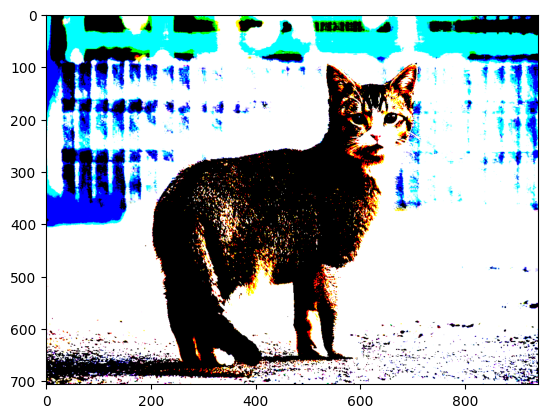

In [6]:
curr_con = ImageEnhance.Contrast(image)
# new_con = 4
new_con = 100

# Contrast enhanced by a factor of 0.3
img_contrasted = curr_con.enhance(new_con)

# shows updated image in image viewer
plt.imshow(img_contrasted)

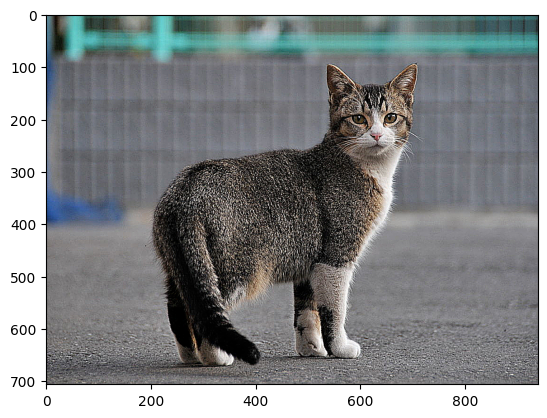

In [7]:
# Enhance Sharpness
curr_sharp = ImageEnhance.Sharpness(image)
# new_sharp = 3
new_sharp = 8.3

# Sharpness enhanced by a factor of 8.3
img_sharped = curr_sharp.enhance(new_sharp)

# shows updated image in image viewer
plt.imshow(img_sharped)

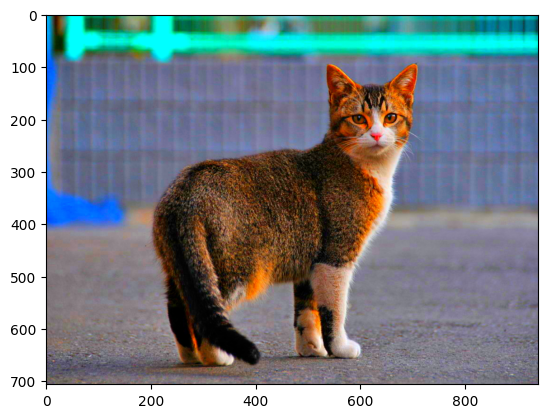

In [8]:
curr_col = ImageEnhance.Color(image)
new_col = 5

# Color level enhanced by a factor of 2.5
img_colored = curr_col.enhance(new_col)

# shows updated image in image viewer
plt.imshow(img_colored )

### 1. Eksperimen Sistematis Koefisien Image Enhancement

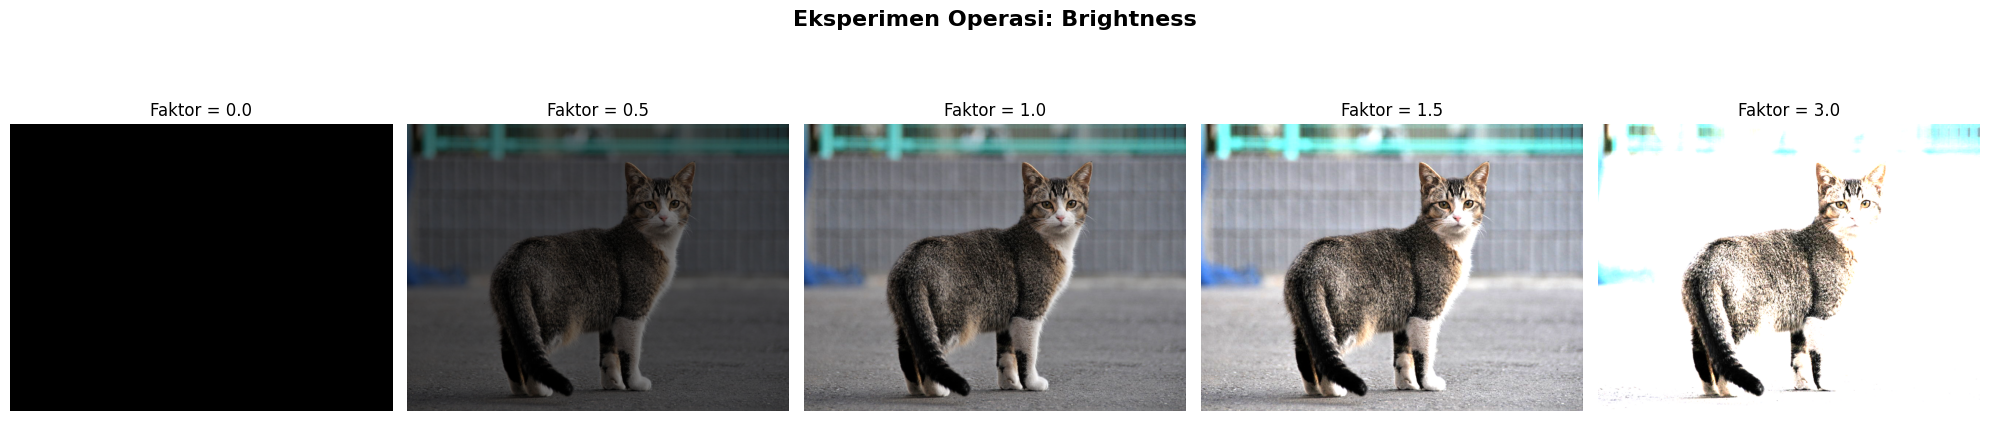

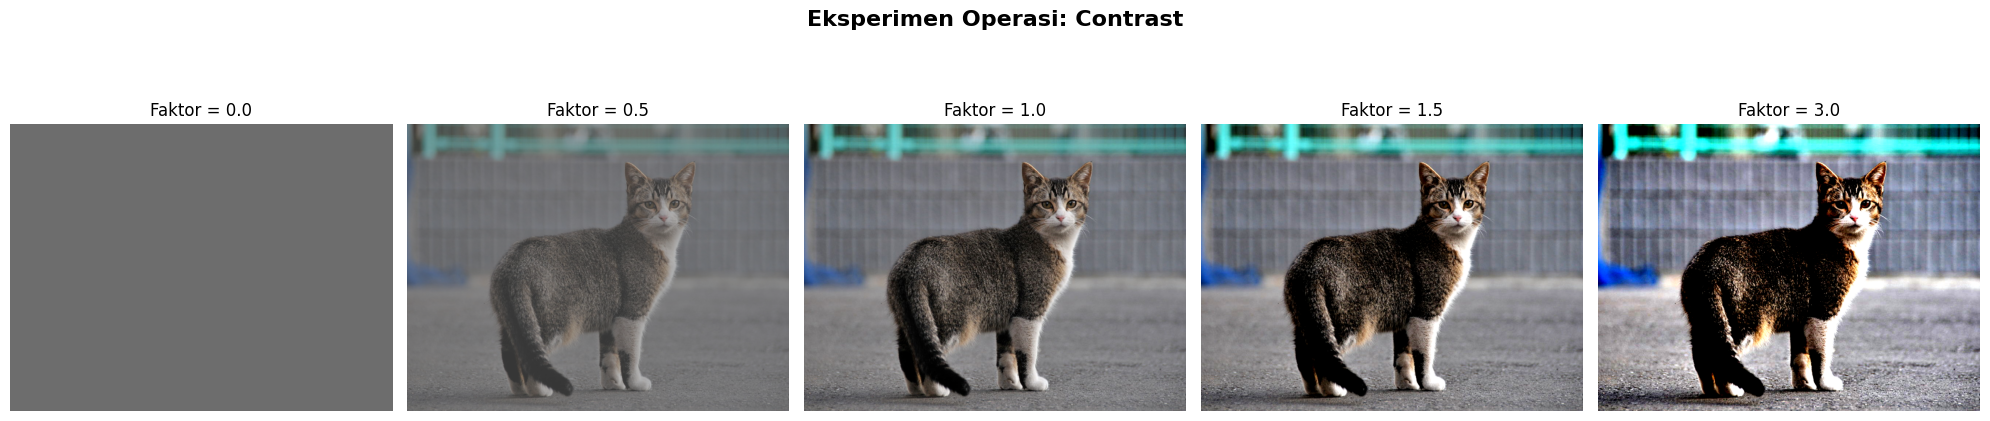

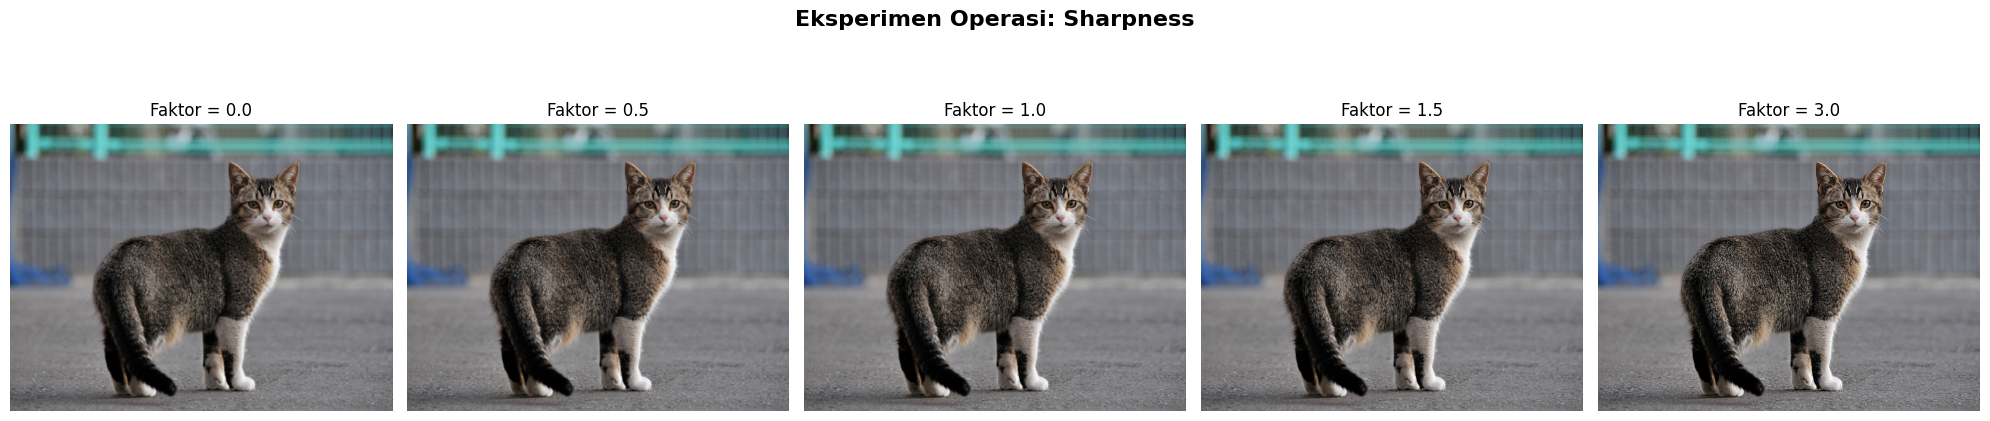

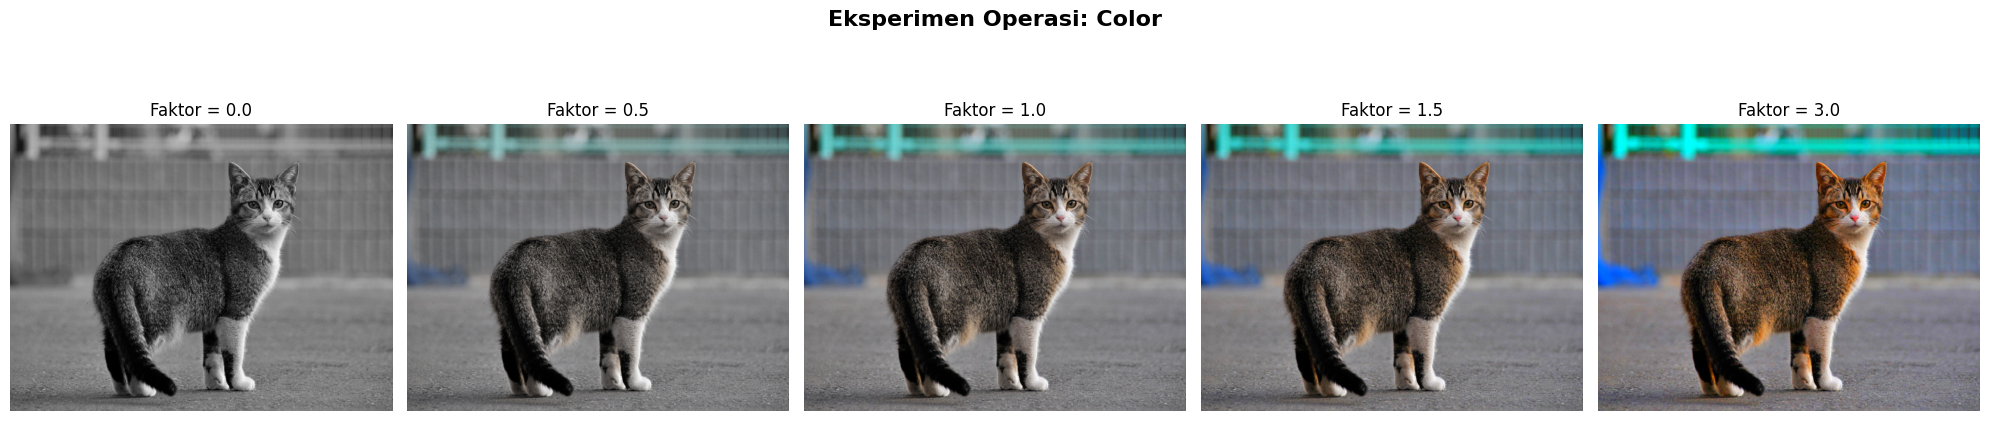

In [9]:
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

# Menggunakan variabel 'image' yang sudah berhasil dimuat sebelumnya di sel atas
orig_image = image

# Daftar parameter yang akan diuji untuk masing-masing operasi
coefficients = [0.0, 0.5, 1.0, 1.5, 3.0]

operations = {
    'Brightness': ImageEnhance.Brightness,
    'Contrast': ImageEnhance.Contrast,
    'Sharpness': ImageEnhance.Sharpness,
    'Color': ImageEnhance.Color
}

# Membuat plot perbandingan untuk setiap operasi
for op_name, op_class in operations.items():
    fig, axes = plt.subplots(1, len(coefficients), figsize=(20, 5))
    fig.suptitle(f'Eksperimen Operasi: {op_name}', fontsize=16, fontweight='bold')

    enhancer = op_class(orig_image)

    for i, coef in enumerate(coefficients):
        # Melakukan enhancement sesuai koefisien
        enhanced_img = enhancer.enhance(coef)

        # Menampilkan gambar pada subplot
        axes[i].imshow(enhanced_img)
        axes[i].set_title(f'Faktor = {coef}')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

### 3. Eksperimen Menggunakan Gambar Baru (`kopi.bmp`)
Mari kita amati apakah ada perbedaan efek visual ketika menggunakan gambar kopi dengan format `.bmp` ini.

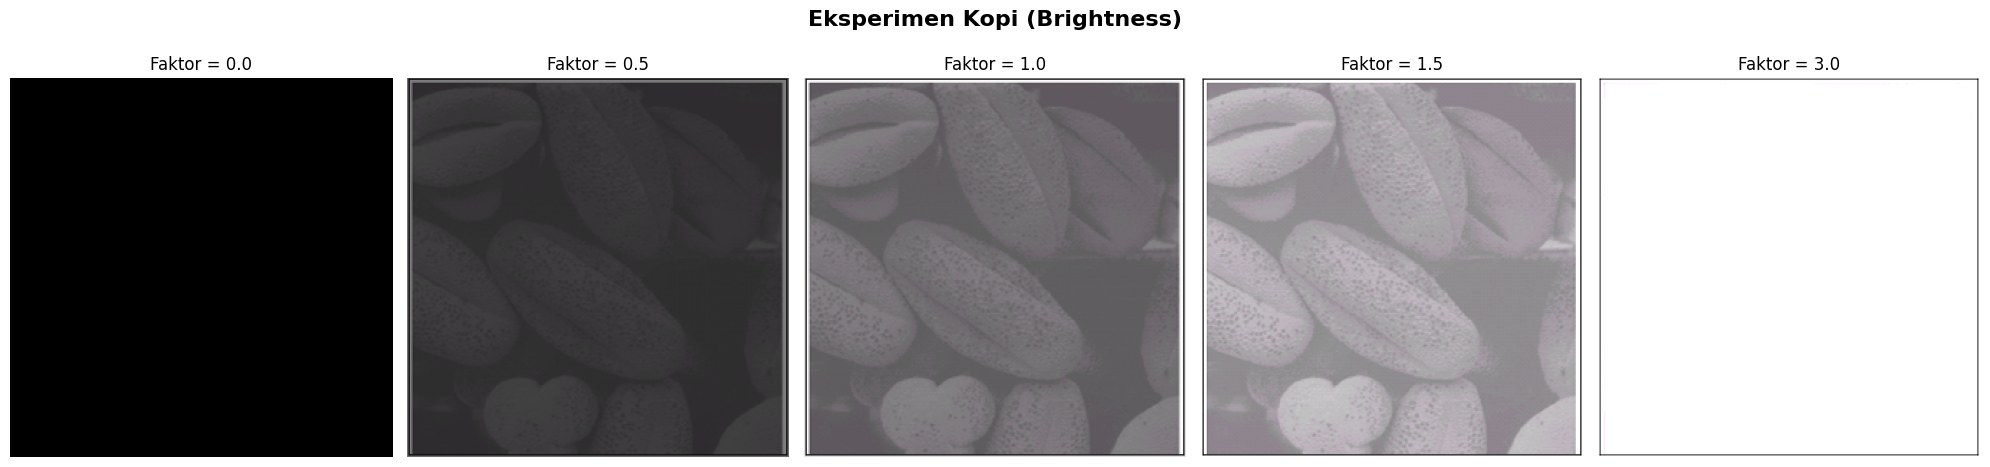

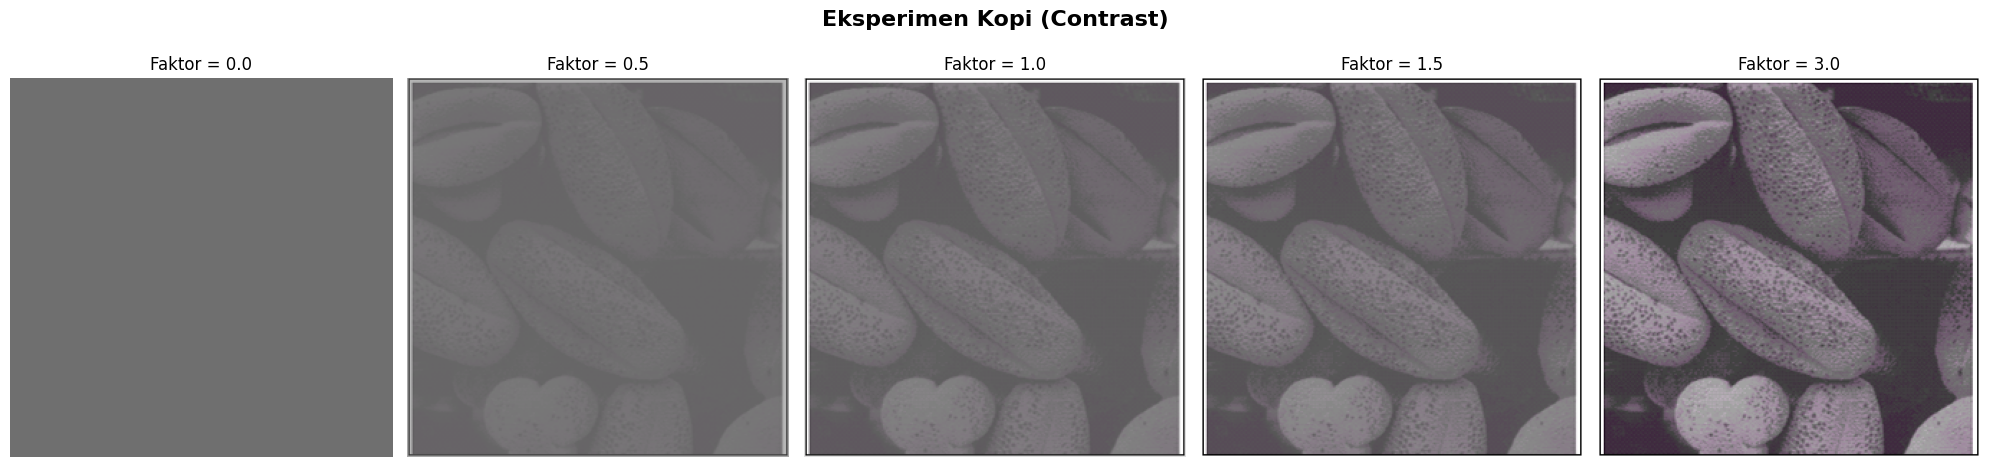

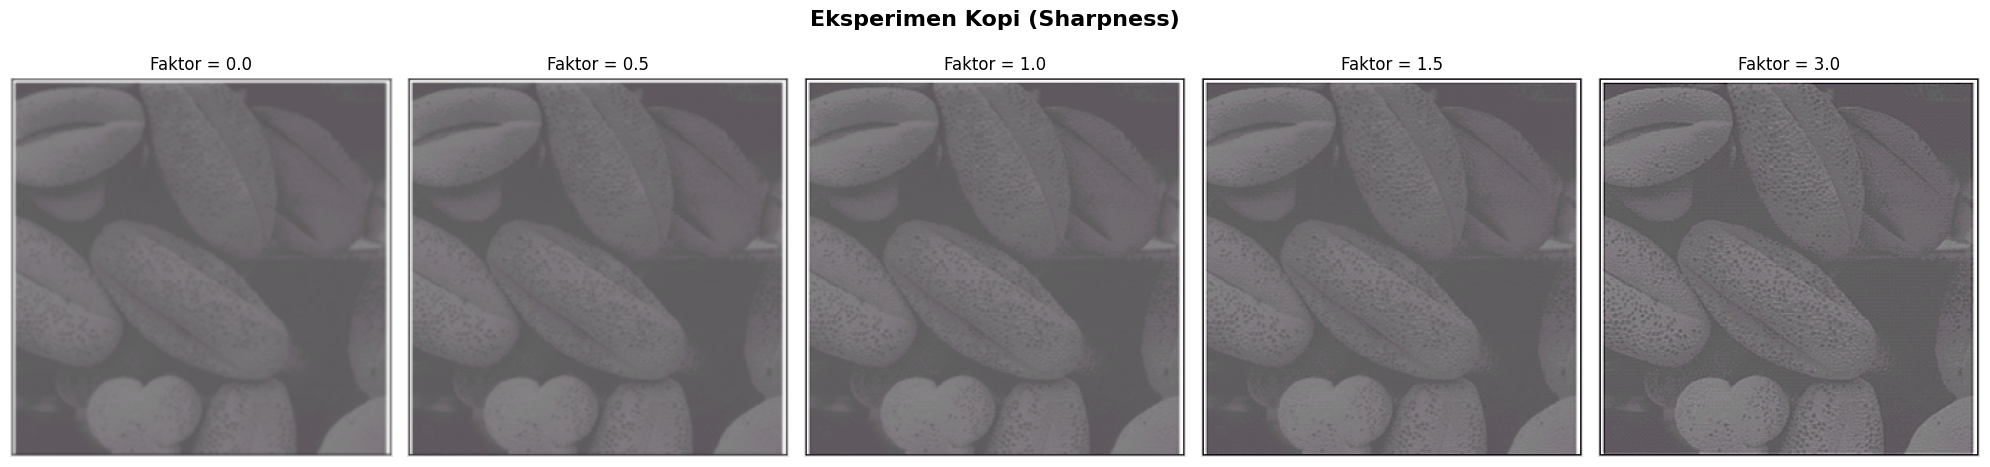

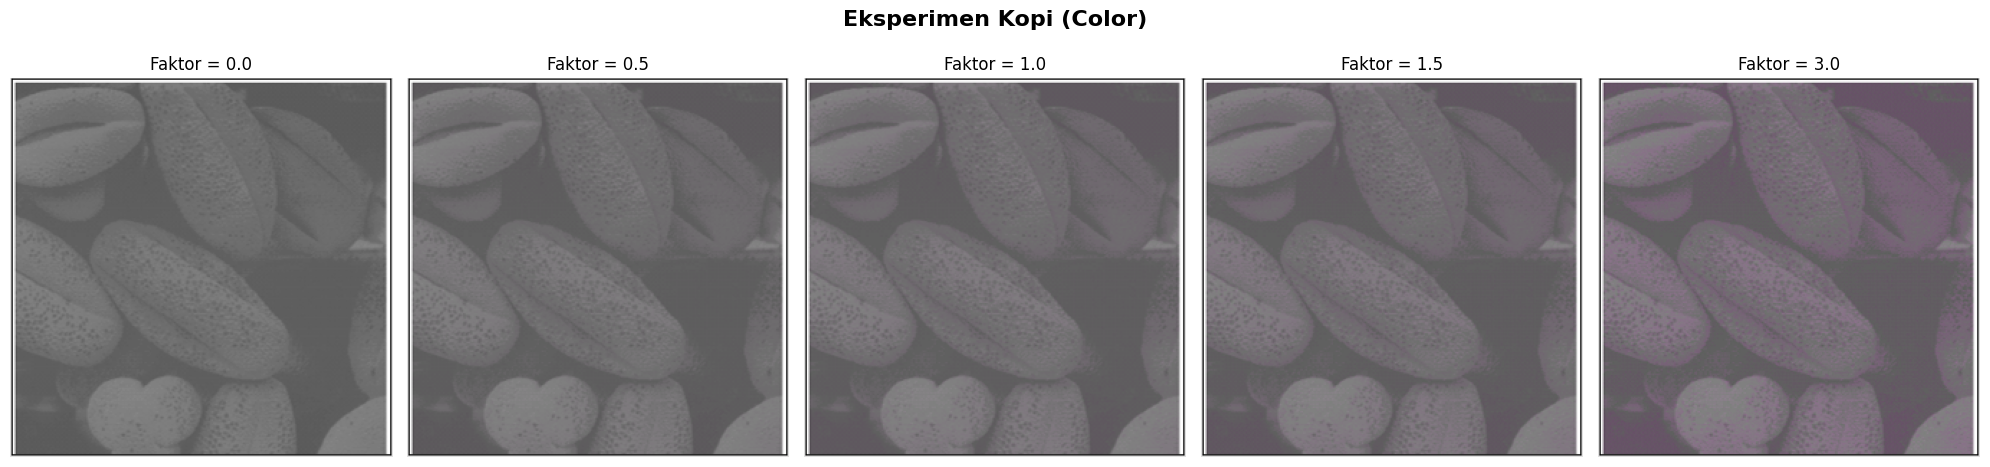

In [10]:
import os
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

kopi_path = '/content/drive/MyDrive/Image_proc/kopi.bmp'

if os.path.exists(kopi_path):
    kopi_image = Image.open(kopi_path)

    # Menjalankan eksperimen sistematik yang sama pada gambar kopi
    for op_name, op_class in operations.items():
        fig, axes = plt.subplots(1, len(coefficients), figsize=(20, 5))
        fig.suptitle(f'Eksperimen Kopi ({op_name})', fontsize=16, fontweight='bold')

        enhancer = op_class(kopi_image)

        for i, coef in enumerate(coefficients):
            enhanced_img = enhancer.enhance(coef)
            axes[i].imshow(enhanced_img)
            axes[i].set_title(f'Faktor = {coef}')
            axes[i].axis('off')

        plt.tight_layout()
        plt.show()
else:
    print(f"File tidak ditemukan di path: {kopi_path}. Pastikan file tersebut sudah ada di Google Drive Anda.")

### 2. Draf Laporan Analisis Pengaruh Koefisien

Berdasarkan hasil visualisasi di atas, berikut adalah bentuk pelaporan analisis yang dapat Anda gunakan untuk tugas Anda:

| No | Operasi | Nilai Koefisien ($F$) | Pengamatan Visual / Pengaruh Terhadap Gambar |
|---|---|---|---|
| **1** | **Brightness** | $F = 0.0$ <br> $0.0 < F < 1.0$ <br> $F = 1.0$ <br> $F > 1.0$ | Gambar menjadi hitam sepenuhnya.<br>Gambar menjadi lebih redup/gelap dari aslinya.<br>Gambar kembali ke kondisi asli (normal).<br>Gambar menjadi lebih terang. Jika terlalu tinggi (misal $> 2.5$), detail gambar akan hilang karena terlalu putih (*overexposed*). |
| **2** | **Contrast** | $F = 0.0$ <br> $0.0 < F < 1.0$ <br> $F = 1.0$ <br> $F > 1.0$ | Gambar menjadi abu-abu solid/datar (tanpa perbedaan warna).<br>Kontras berkurang, gambar terlihat pudar dan berkabut.<br>Gambar kembali ke kondisi asli (normal).<br>Perbedaan area gelap dan terang semakin tajam. Jika terlalu tinggi (misal $100.0$), gambar mengalami saturasi ekstrem (*clipping*) sehingga pixel hanya menjadi hitam atau putih pekat. |
| **3** | **Sharpness** | $F = 0.0$ <br> $0.0 < F < 1.0$ <br> $F = 1.0$ <br> $F > 1.0$ | Gambar menjadi sangat buram (*blurred*).<br>Ketajaman berkurang secara halus.<br>Gambar kembali ke kondisi asli (normal).<br>Tepi-tepi objek (*edges*) menjadi lebih tajam dan jelas. Jika terlalu tinggi, akan muncul efek *noise* atau bintik kasar (artifak tajam). |
| **4** | **Color** | $F = 0.0$ <br> $0.0 < F < 1.0$ <br> $F = 1.0$ <br> $F > 1.0$ | Gambar berubah menjadi hitam-putih (*grayscale*).<br>Warna gambar memudar (desaturasi).<br>Gambar kembali ke kondisi asli (normal).<br>Warna menjadi lebih hidup, mencolok, dan pekat (*oversaturated*). |

### Kesimpulan Umum:
* **Faktor $= 1.0$** selalu menghasilkan gambar asli tanpa perubahan.
* **Faktor $< 1.0$** mengurangi intensitas dari efek yang diberikan (meredupkan, memudarkan, memburamkan).
* **Faktor $> 1.0$** meningkatkan intensitas efek tersebut. Nilai yang terlalu tinggi akan merusak kualitas gambar (terjadi *clipping*, *overexposure*, atau *noise* berlebih).